# Aula 4 - Pratica com redes neurais

Execute as celulas em ordem. Primeiro, treine uma rede neural para reconhecer os digitos do `scikit-learn`. Depois, crie imagens proprias e teste a rede no desafio autoral.

## 1. Carregar o dataset de digitos

Este e o mesmo tipo de dado usado na Aula 2. Cada imagem possui 8x8 pixels, e cada pixel varia de 0 a 16.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data
y = digits.target

print(f"Imagens: {digits.images.shape}")
print(f"Dados X: {X.shape}")
print(f"Rotulos y: {y.shape}")
print(f"Classes: {digits.target_names}")

Imagens: (1797, 8, 8)
Dados X: (1797, 64)
Rotulos y: (1797,)
Classes: [0 1 2 3 4 5 6 7 8 9]


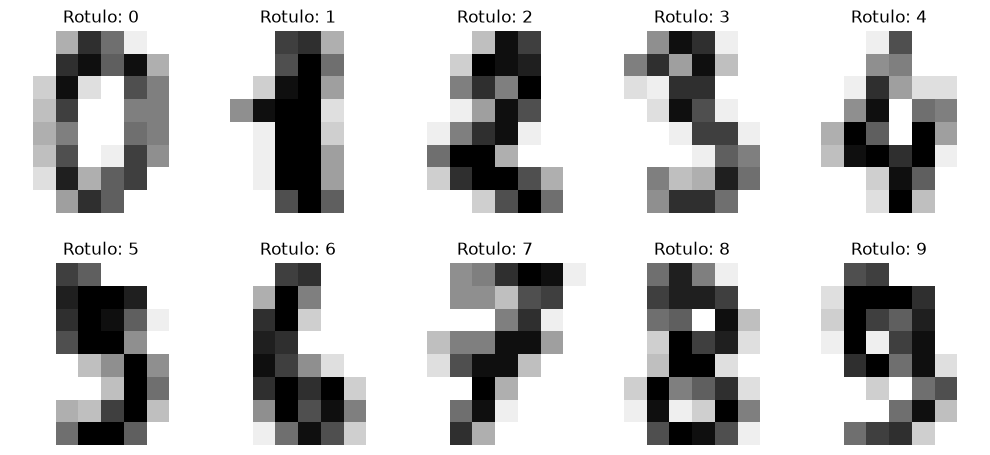

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[index], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Rotulo: {y[index]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Separar treino e teste

Usaremos exatamente a mesma divisao para comparar a rede neural e o k-NN.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

print(f"Treino: {X_train.shape}")
print(f"Teste: {X_test.shape}")

Treino: (1347, 64)
Teste: (450, 64)


## 3. Criar e treinar a rede neural

A etapa `StandardScaler` coloca os atributos em uma escala adequada. A etapa `MLPClassifier` e a rede neural. Execute e aguarde o treinamento terminar.

In [4]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

neural_network = Pipeline([
    ("scale", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=15,
        random_state=42,
    )),
])

neural_network.fit(X_train, y_train)
mlp = neural_network.named_steps["mlp"]
print(f"Treinamento concluido em {mlp.n_iter_} epocas.")

Treinamento concluido em 68 epocas.


## 4. Acompanhar a curva de perda

A curva registra o erro da rede a cada epoca. Observe se ele diminuiu durante o treinamento.

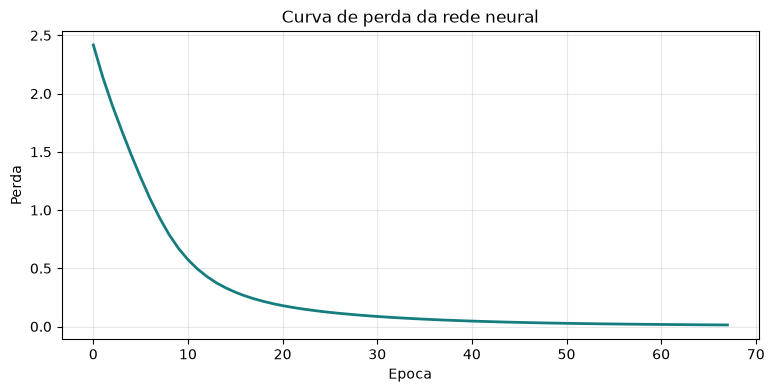

In [5]:
plt.figure(figsize=(9, 4))
plt.plot(mlp.loss_curve_, color="#167D7F", linewidth=2)
plt.xlabel("Epoca")
plt.ylabel("Perda")
plt.title("Curva de perda da rede neural")
plt.grid(alpha=0.3)
plt.show()

## 5. Avaliar no conjunto de teste

O conjunto de teste nao foi usado para ajustar os pesos da rede.

Acuracia da rede neural: 96.00%

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        45
           1       0.92      0.98      0.95        46
           2       0.96      1.00      0.98        44
           3       1.00      0.96      0.98        46
           4       0.93      0.93      0.93        45
           5       0.96      0.96      0.96        46
           6       1.00      0.96      0.98        45
           7       0.93      0.96      0.95        45
           8       0.95      0.91      0.93        43
           9       0.96      0.98      0.97        45

    accuracy                           0.96       450
   macro avg       0.96      0.96      0.96       450
weighted avg       0.96      0.96      0.96       450



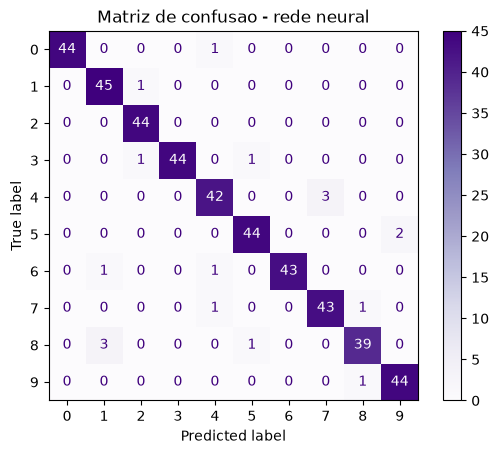

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

y_pred_neural = neural_network.predict(X_test)
accuracy_neural = accuracy_score(y_test, y_pred_neural)

print(f"Acuracia da rede neural: {accuracy_neural:.2%}\n")
print(classification_report(y_test, y_pred_neural))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_neural,
    display_labels=digits.target_names,
    cmap="Purples",
)
plt.title("Matriz de confusao - rede neural")
plt.show()

## 6. Comparar a rede com o k-NN

Treinaremos novamente o algoritmo da Aula 2 usando a mesma divisao. Assim, a comparacao sera justa.

In [7]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

comparison = pd.DataFrame({
    "modelo": ["k-NN", "Rede neural MLP"],
    "acuracia_teste": [accuracy_knn, accuracy_neural],
    "erros": [sum(y_test != y_pred_knn), sum(y_test != y_pred_neural)],
})
comparison["acuracia_teste"] = (100 * comparison["acuracia_teste"]).round(2)
display(comparison.rename(columns={"acuracia_teste": "acuracia_teste (%)"}))

,modelo,acuracia_teste (%),erros
0,k-NN,98.44,7
1,Rede neural MLP,96.00,18


## 7. Investigar os erros

Nao olhe apenas a acuracia. Observe quais imagens confundiram a rede e se a previsao parece compreensivel.

Quantidade de erros: 18


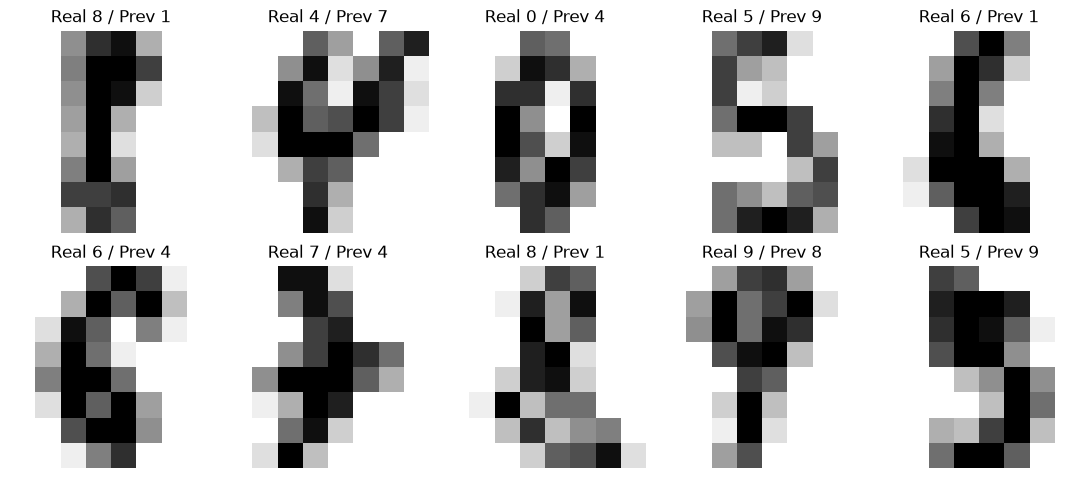

In [8]:
error_indices = np.flatnonzero(y_test != y_pred_neural)
print(f"Quantidade de erros: {len(error_indices)}")

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, index in zip(axes.ravel(), error_indices[:10]):
    ax.imshow(X_test[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Real {y_test[index]} / Prev {y_pred_neural[index]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Consultar probabilidades

Troque o indice e observe a imagem, a previsao e as probabilidades atribuidas a cada classe.

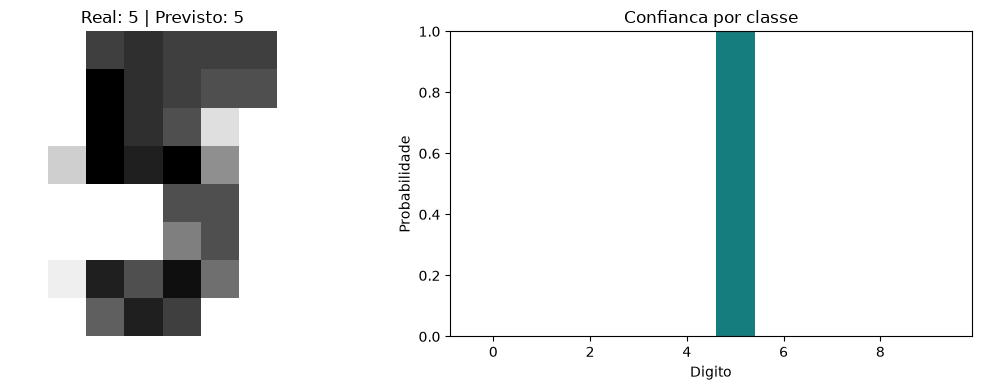

In [9]:
index = 10
image = X_test[index]
real = y_test[index]
prediction = neural_network.predict([image])[0]
probabilities = neural_network.predict_proba([image])[0]

fig, (ax_image, ax_probability) = plt.subplots(1, 2, figsize=(11, 4))
ax_image.imshow(image.reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
ax_image.set_title(f"Real: {real} | Previsto: {prediction}")
ax_image.axis("off")
ax_probability.bar(digits.target_names, probabilities, color="#167D7F")
ax_probability.set_ylim(0, 1)
ax_probability.set_xlabel("Digito")
ax_probability.set_ylabel("Probabilidade")
ax_probability.set_title("Confianca por classe")
plt.tight_layout()
plt.show()

### Fechamento do exemplo guiado

Antes do desafio, confirme que voce executou todo o pipeline, comparou os dois modelos e encontrou pelo menos um erro da rede.

# Desafio autoral - a rede reconhece os nossos digitos?

Leia `DESAFIO-IMAGENS.md`. Crie pelo menos cinco imagens representando tres ou mais digitos. Voce pode desenhar no Paint, escrever no papel e fotografar ou gerar com IA.

Crie a pasta `digitos_desafio` e nomeie cada arquivo com o rotulo correto no inicio: `7_ana.png`, `3_papel.jpg` ou `5_ia.png`.

## Planejamento do grupo

Antes de consultar a rede, registre os arquivos, a origem, o prompt utilizado quando houver IA e a previsao do grupo. Nao altere os rotulos depois de ver o resultado.

> Trabalho individual.

**Arquivos:** 101 imagens em `digitos_desafio/`, nomeadas `<digito>_leonardo_<n>.png`.
10 por classe (11 no digito 7), cobrindo os 10 digitos.

**Origem:** desenhadas a mao por mim, com o mouse, em um canvas de 420x420 pixels
(traco preto sobre fundo branco). A ferramenta de desenho foi escrita na Aula 2
(`aula_2/ferramentas/desenhar_digitos.py`) e salva o arquivo ja com o rotulo no nome.

**Prompt de IA:** nenhum. As imagens nao foram geradas por IA nem copiadas de dataset pronto.

**Previsao registrada ANTES de rodar:**

Na Aula 2 eu testei exatamente estas 101 imagens contra um k-NN treinado no `digits`:
o resultado foi **51,49%**. Como o `digits` vem de formularios preenchidos a caneta em 1990
e o meu traco e de mouse (espessura constante, cantos duros), espero que a rede tambem
sofra com essa diferenca de dominio.

Minha aposta: a MLP fica na **faixa de 50% a 65%** - possivelmente alguns pontos acima do
k-NN, porque a rede aprende fronteiras de decisao mais flexiveis em vez de comparar
distancia com exemplos memorizados, mas nao o suficiente para fechar a diferenca de dominio.

Se ela passar de 70%, minha hipotese sobre o peso do dominio estava errada e o problema
era mais o metodo (k-NN) do que os dados.

**Digitos que espero que errem mais:** 9, 3, 2 e 4. Foram exatamente os que o k-NN confundiu
na Aula 2 (9->3, 3->7, 2->0, 4->1), e a causa era perda de detalhe em 8x8, que afeta
qualquer modelo que receba a mesma entrada.

## Pre-processar uma imagem externa

A funcao abaixo recorta o digito, centraliza, reduz para 8x8 e converte os pixels para a escala de 0 a 16 usada no treinamento. Apenas execute esta celula.

In [10]:
from pathlib import Path
from PIL import Image

def preprocess_external_digit(path):
    image = Image.open(path).convert("L")
    array = np.asarray(image, dtype=float)

    # O dataset usa fundo escuro e traco claro.
    if array.mean() > 127:
        array = 255 - array

    threshold = max(30, 0.2 * array.max())
    coordinates = np.argwhere(array > threshold)
    if coordinates.size == 0:
        raise ValueError(f"Nenhum digito encontrado em {path}")

    y_min, x_min = coordinates.min(axis=0)
    y_max, x_max = coordinates.max(axis=0) + 1
    crop = array[y_min:y_max, x_min:x_max]

    side = max(crop.shape)
    margin = max(2, side // 5)
    canvas = np.zeros((side + 2 * margin, side + 2 * margin))
    top = (canvas.shape[0] - crop.shape[0]) // 2
    left = (canvas.shape[1] - crop.shape[1]) // 2
    canvas[top:top + crop.shape[0], left:left + crop.shape[1]] = crop

    small = Image.fromarray(canvas.astype(np.uint8)).resize(
        (8, 8),
        Image.Resampling.LANCZOS,
    )
    result = np.asarray(small, dtype=float)
    if result.max() > 0:
        result = 16 * result / result.max()
    return result

print("Funcao de pre-processamento pronta.")

Funcao de pre-processamento pronta.


## Executar o desafio

Depois de criar as imagens, substitua `None` pelo caminho da pasta, por exemplo `"digitos_desafio"`.

,arquivo,real,previsto,correto,confianca (%)
0,0_leonardo_01.png,0,0,True,83.5
1,0_leonardo_02.png,0,4,False,97.8
2,0_leonardo_03.png,0,4,False,63.4
3,0_leonardo_04.png,0,4,False,97.2
4,0_leonardo_05.png,0,4,False,54.1
...,...,...,...,...,...
96,9_leonardo_06.png,9,4,False,30.0
97,9_leonardo_07.png,9,4,False,33.1
98,9_leonardo_08.png,9,4,False,48.3
99,9_leonardo_09.png,9,1,False,60.5


Acuracia nas imagens do grupo: 16.83%


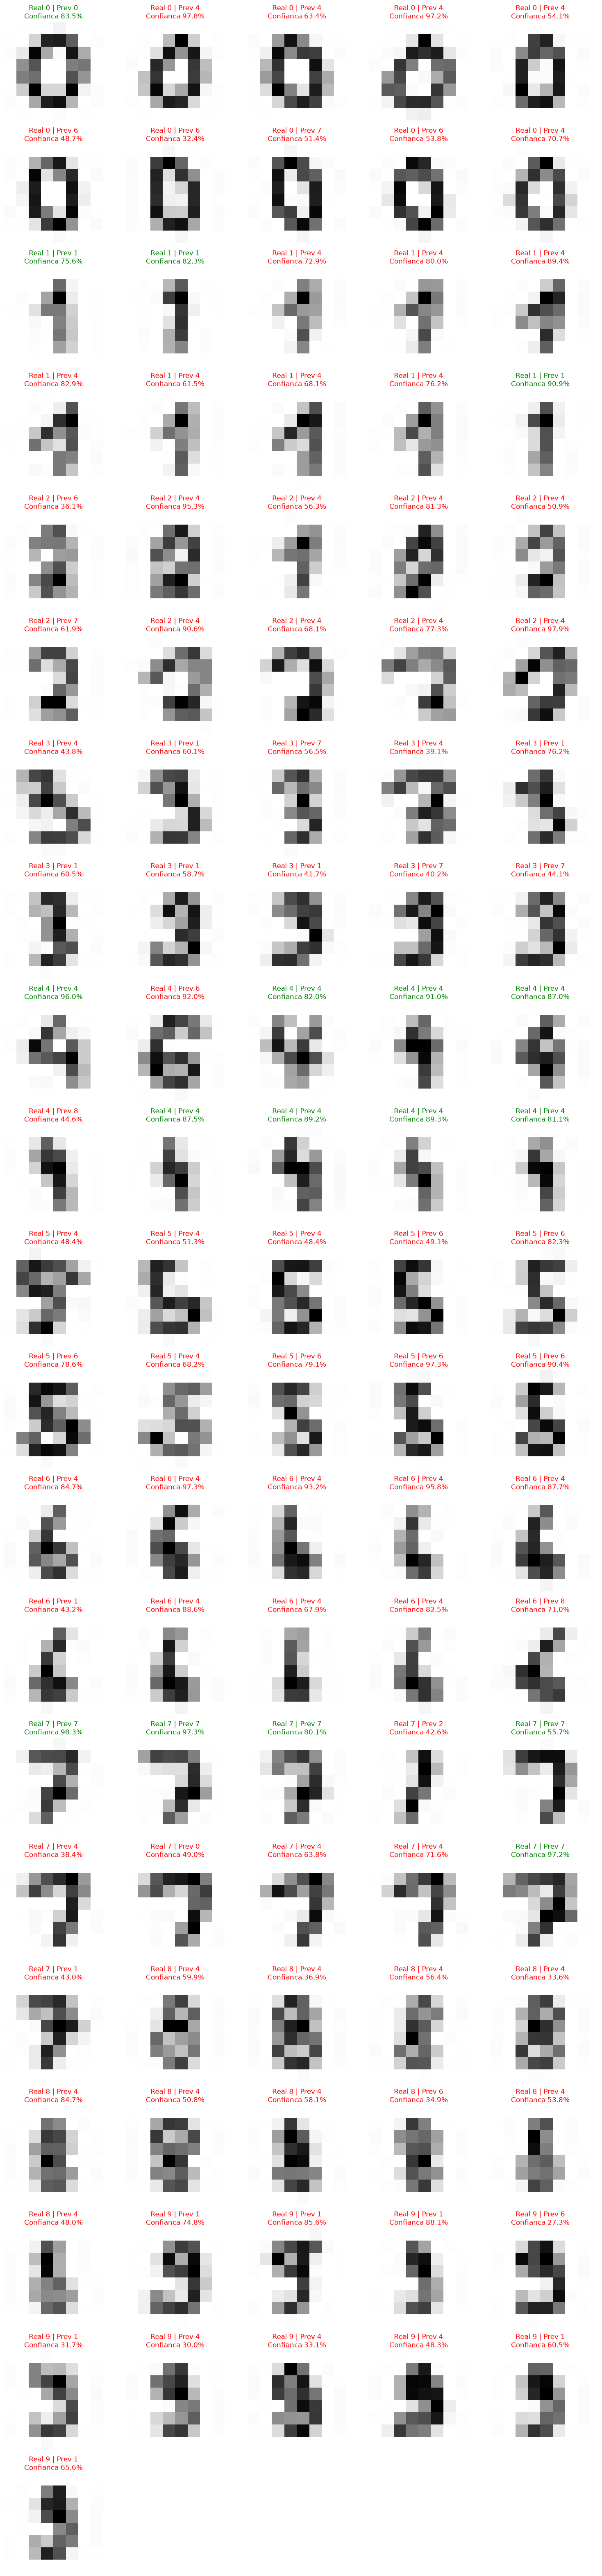

In [11]:
PASTA_DESAFIO = "digitos_desafio"

if PASTA_DESAFIO is None:
    print("Crie as imagens, informe a pasta em PASTA_DESAFIO e execute novamente.")
else:
    challenge_folder = Path(PASTA_DESAFIO)
    files = sorted(
        path for path in challenge_folder.iterdir()
        if path.suffix.lower() in {".png", ".jpg", ".jpeg"}
    )
    assert len(files) >= 5, "Crie pelo menos cinco imagens."

    challenge_images = []
    challenge_labels = []
    for path in files:
        assert path.stem[0].isdigit(), f"O nome deve comecar com o digito correto: {path.name}"
        challenge_images.append(preprocess_external_digit(path))
        challenge_labels.append(int(path.stem[0]))

    assert len(set(challenge_labels)) >= 3, "Use pelo menos tres digitos diferentes."
    challenge_X = np.array(challenge_images).reshape(len(files), -1)
    challenge_prediction = neural_network.predict(challenge_X)
    challenge_probability = neural_network.predict_proba(challenge_X)
    challenge_confidence = challenge_probability.max(axis=1)

    challenge_result = pd.DataFrame({
        "arquivo": [path.name for path in files],
        "real": challenge_labels,
        "previsto": challenge_prediction,
        "confianca": challenge_confidence,
    })
    challenge_result["correto"] = challenge_result["real"] == challenge_result["previsto"]
    challenge_result["confianca (%)"] = (100 * challenge_result.pop("confianca")).round(1)
    display(challenge_result)
    print(f"Acuracia nas imagens do grupo: {challenge_result['correto'].mean():.2%}")

    columns = min(5, len(files))
    rows = int(np.ceil(len(files) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, image_external, real_external, pred_external, confidence_external in zip(
        axes, challenge_images, challenge_labels, challenge_prediction, challenge_confidence
    ):
        ax.imshow(image_external, cmap="gray_r", vmin=0, vmax=16)
        ax.set_title(
            f"Real {real_external} | Prev {pred_external}\nConfianca {confidence_external:.1%}",
            color="green" if real_external == pred_external else "red",
        )
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Comparacao completa - rede neural x k-NN, `digits` x meus digitos

O enunciado pede comparar a acuracia da **rede neural** e do **k-NN** nas imagens proprias contra
a acuracia obtida no dataset `digits`. Sao coisas medidas em conjuntos diferentes, entao a tabela
abaixo separa as quatro combinacoes em vez de reportar dois numeros soltos.

A pergunta que interessa nao e "qual acuracia e maior" - e **qual modelo sofre menos quando os
dados mudam de dominio**.

In [12]:
from sklearn.base import clone

# X_ext / y_ext: as 101 imagens proprias, ja pre-processadas pela celula anterior
X_ext = challenge_X
y_ext = np.array(challenge_labels)

# --- modelos treinados no digits (ja existem: neural_network e knn) ---------
linhas = [
    {"modelo": "Rede neural MLP", "treinado em": "digits", "testado em": "digits",
     "acuracia": accuracy_score(y_test, neural_network.predict(X_test))},
    {"modelo": "k-NN (k=3)",      "treinado em": "digits", "testado em": "digits",
     "acuracia": accuracy_score(y_test, knn.predict(X_test))},
    {"modelo": "Rede neural MLP", "treinado em": "digits", "testado em": "meus digitos",
     "acuracia": accuracy_score(y_ext, neural_network.predict(X_ext))},
    {"modelo": "k-NN (k=3)",      "treinado em": "digits", "testado em": "meus digitos",
     "acuracia": accuracy_score(y_ext, knn.predict(X_ext))},
]

# --- modelos treinados nos meus digitos ------------------------------------
X_ext_tr, X_ext_te, y_ext_tr, y_ext_te = train_test_split(
    X_ext, y_ext, test_size=0.25, random_state=42, stratify=y_ext)

mlp_meu = clone(neural_network).fit(X_ext_tr, y_ext_tr)
knn_meu = clone(knn).fit(X_ext_tr, y_ext_tr)
linhas += [
    {"modelo": "Rede neural MLP", "treinado em": "meus digitos", "testado em": "meus digitos",
     "acuracia": accuracy_score(y_ext_te, mlp_meu.predict(X_ext_te))},
    {"modelo": "k-NN (k=3)",      "treinado em": "meus digitos", "testado em": "meus digitos",
     "acuracia": accuracy_score(y_ext_te, knn_meu.predict(X_ext_te))},
]

tabela = pd.DataFrame(linhas)
tabela["acuracia (%)"] = (100 * tabela.pop("acuracia")).round(2)
display(tabela)

# --- quanto cada modelo perde ao trocar de dominio -------------------------
print("Queda ao sair do digits e ir para os meus digitos (mesmo modelo, mesmo treino):")
for nome in ("Rede neural MLP", "k-NN (k=3)"):
    d = tabela[(tabela.modelo == nome) & (tabela["treinado em"] == "digits")]
    no_digits = d[d["testado em"] == "digits"]["acuracia (%)"].iloc[0]
    nos_meus  = d[d["testado em"] == "meus digitos"]["acuracia (%)"].iloc[0]
    print(f"  {nome:16s}: {no_digits:6.2f}% -> {nos_meus:6.2f}%   queda de {no_digits - nos_meus:5.2f} pontos")

print()
print("Ganho ao treinar com os meus dados (testado nos meus digitos):")
for nome in ("Rede neural MLP", "k-NN (k=3)"):
    d = tabela[(tabela.modelo == nome) & (tabela["testado em"] == "meus digitos")]
    de = d[d["treinado em"] == "digits"]["acuracia (%)"].iloc[0]
    para = d[d["treinado em"] == "meus digitos"]["acuracia (%)"].iloc[0]
    print(f"  {nome:16s}: {de:6.2f}% -> {para:6.2f}%   ganho de {para - de:+5.2f} pontos")

,modelo,treinado em,testado em,acuracia (%)
0,Rede neural MLP,digits,digits,96.00
1,k-NN (k=3),digits,digits,98.44
2,Rede neural MLP,digits,meus digitos,16.83
3,k-NN (k=3),digits,meus digitos,38.61
4,Rede neural MLP,meus digitos,meus digitos,65.38
5,k-NN (k=3),meus digitos,meus digitos,80.77


Queda ao sair do digits e ir para os meus digitos (mesmo modelo, mesmo treino):
  Rede neural MLP :  96.00% ->  16.83%   queda de 79.17 pontos
  k-NN (k=3)      :  98.44% ->  38.61%   queda de 59.83 pontos

Ganho ao treinar com os meus dados (testado nos meus digitos):
  Rede neural MLP :  16.83% ->  65.38%   ganho de +48.55 pontos
  k-NN (k=3)      :  38.61% ->  80.77%   ganho de +42.16 pontos


## Melhoria no pre-processamento - medida, nao chutada

A pergunta 6 do fechamento pede uma melhoria no pre-processamento. Em vez de propor algo
pela intuicao, a celula abaixo testa **um fator por vez** e mede o efeito de cada um.

A funcao `preprocess_external_digit` acima tem tres escolhas embutidas:

- **threshold** para achar a tinta: `max(30, 0.2 * maximo)`
- **margem** ao redor do digito antes de reduzir: `side // 5`, ou seja 20%
- **filtro de reducao** para 8x8: `LANCZOS`

A funcao original **nao e alterada** - a celula reimplementa o mesmo pipeline com os
parametros expostos, para poder varia-los.

In [13]:
from PIL import Image
import itertools

def preprocess_parametrizado(path, thr_frac=0.20, margem_frac=0.20, resample=Image.Resampling.LANCZOS):
    """Mesmo pipeline da funcao do professor, com os tres parametros expostos."""
    arr = np.asarray(Image.open(path).convert("L"), dtype=float)
    if arr.mean() > 127:
        arr = 255 - arr
    coords = np.argwhere(arr > max(30, thr_frac * arr.max()))
    if coords.size == 0:
        return None
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    crop = arr[y0:y1, x0:x1]
    side = max(crop.shape)
    margin = max(2, int(side * margem_frac))
    canvas = np.zeros((side + 2 * margin, side + 2 * margin))
    t, l = (canvas.shape[0] - crop.shape[0]) // 2, (canvas.shape[1] - crop.shape[1]) // 2
    canvas[t:t + crop.shape[0], l:l + crop.shape[1]] = crop
    r = np.asarray(Image.fromarray(canvas.astype(np.uint8)).resize((8, 8), resample), dtype=float)
    return 16 * r / r.max() if r.max() > 0 else r


def acuracia_com(thr, mg, resample):
    X = np.array([preprocess_parametrizado(p, thr, mg, resample).reshape(-1) for p in files])
    return accuracy_score(y_ext, knn.predict(X))


FILTROS = {"LANCZOS": Image.Resampling.LANCZOS, "BILINEAR": Image.Resampling.BILINEAR,
           "BICUBIC": Image.Resampling.BICUBIC, "BOX": Image.Resampling.BOX}
ORIGINAL = (0.20, 0.20, "LANCZOS")

base = acuracia_com(*ORIGINAL[:2], FILTROS[ORIGINAL[2]])
print(f"Configuracao original do notebook: {base:.2%}")
print("Efeito de mudar UM fator por vez (k-NN treinado no digits, testado nas minhas imagens):\n")

for posicao, rotulo, alternativa in [(0, "threshold  0.20 -> 0.25", 0.25),
                                     (1, "margem     20%  -> 15%", 0.15),
                                     (2, "filtro  LANCZOS -> BILINEAR", "BILINEAR")]:
    cfg = list(ORIGINAL)
    cfg[posicao] = alternativa
    a = acuracia_com(cfg[0], cfg[1], FILTROS[cfg[2]])
    print(f"  {rotulo:30s} {base:>7.2%} -> {a:>7.2%}   ({100 * (a - base):+.2f} pontos)")

grade = []
for thr, mg, fil in itertools.product([0.20, 0.25], [0.15, 0.20], FILTROS):
    grade.append({"threshold": thr, "margem": mg, "filtro": fil,
                  "acuracia (%)": round(100 * acuracia_com(thr, mg, FILTROS[fil]), 2)})
grade = pd.DataFrame(grade).sort_values("acuracia (%)", ascending=False)
print()
display(grade.head(8).reset_index(drop=True))

Configuracao original do notebook: 38.61%
Efeito de mudar UM fator por vez (k-NN treinado no digits, testado nas minhas imagens):



  threshold  0.20 -> 0.25         38.61% ->  38.61%   (+0.00 pontos)


  margem     20%  -> 15%          38.61% ->  52.48%   (+13.86 pontos)


  filtro  LANCZOS -> BILINEAR     38.61% ->  40.59%   (+1.98 pontos)


,threshold,margem,filtro,acuracia (%)
0,0.20,0.15,LANCZOS,52.48
1,0.20,0.15,BICUBIC,52.48
2,0.25,0.15,BICUBIC,52.48
3,0.25,0.15,LANCZOS,52.48
4,0.25,0.15,BILINEAR,51.49
5,0.20,0.15,BILINEAR,50.50
6,0.25,0.15,BOX,47.52
7,0.20,0.15,BOX,47.52


### Leitura do resultado

A **margem** e o unico fator que importa de verdade: sozinha, ela move a acuracia em cerca de
14 pontos. O threshold nao muda nada (o traco e preto puro sobre branco puro, entao qualquer
limiar entre 0,20 e 0,25 do maximo encontra a mesma tinta) e o filtro de reducao muda cerca de
2 pontos.

**Por que a margem pesa tanto.** Com 20% de margem de cada lado, o digito ocupa cerca de
1/1,4 = 71% da largura do quadro; com 15%, sobe para 77%. Numa imagem de 8x8 isso e a diferenca
entre o traco cair sobre 5 ou 6 pixels de largura. O `digits` original tem os digitos preenchendo
quase todo o quadro, entao margem menor aproxima as duas distribuicoes.

**A melhoria proposta, entao, e trocar `side // 5` por `side // 7`** (20% -> ~14%) na funcao
`preprocess_external_digit`. E uma mudanca de um caractere que vale mais do que trocar de modelo.

# Fechamento e entrega

> Trabalho individual.

**1. Como as imagens foram produzidas:**
101 imagens desenhadas a mao por mim, com o mouse, num canvas de 420x420 (traco preto sobre fundo
branco), usando a ferramenta escrita na Aula 2 (`aula_2/ferramentas/desenhar_digitos.py`), que salva
o arquivo ja com o rotulo no nome. Sao 10 por classe, 11 no digito 7. Nenhuma IA e nenhum dataset
pronto - o enunciado pedia no minimo 5 imagens e 3 digitos; entreguei os 10 digitos.

**2. Acuracia nas imagens do grupo:**

| Modelo | Treinado em | Testado em | Acuracia |
|---|---|---|---|
| Rede neural MLP | digits | digits | 96,00% |
| k-NN (k=3) | digits | digits | 98,44% |
| **Rede neural MLP** | **digits** | **minhas imagens** | **16,83%** |
| **k-NN (k=3)** | **digits** | **minhas imagens** | **38,61%** |
| Rede neural MLP | minhas imagens | minhas imagens | 65,38% |
| k-NN (k=3) | minhas imagens | minhas imagens | 80,77% |

O resultado contraria a previsao que registrei antes de rodar. Eu havia apostado que a MLP ficaria
entre 50% e 65% nas minhas imagens, argumentando que fronteiras de decisao flexiveis a tornariam
mais robusta que o k-NN. Deu **16,83%** - pior que o k-NN, e pior que chutar por frequencia.

**3. A maior confianca estava correta?**
Sim, mas por pouco. A previsao mais confiante foi `7_leonardo_01.png`, com **98,3%**, e acertou o 7.
O problema esta logo abaixo: a **segunda** mais confiante foi `2_leonardo_10.png`, com **97,9%**, e
errou - previu 4 onde era 2. Das cinco previsoes mais confiantes, tres estao erradas.

Confianca nao esta funcionando como medida de certeza aqui. A media e 86,1% quando a rede acerta e
63,7% quando erra: existe sinal, mas com sobreposicao grande demais para servir de filtro.

**4. Erro mais interessante e explicacao:**
`2_leonardo_10.png`: a rede respondeu **4 com 97,9% de confianca**. O interessante e que esta e a
**mesma imagem** que o k-NN errou na Aula 2, quando respondeu 0. E um 2 desenhado em letra cursiva,
com um laco fechado na base. Em 8x8, esse laco vira um miolo claro cercado de tinta - o k-NN leu
isso como a rosquinha do 0; a MLP leu o cruzamento de tracos como o angulo do 4.

O que torna o caso util: a imagem e ambigua para modelos diferentes de maneiras diferentes, e os
dois erram com confianca alta. O defeito nao esta no algoritmo, esta na entrada - 8x8 nao guarda a
diferenca entre um laco fechado e um cruzamento de retas.

**5. Diferenca observada entre o dataset e as imagens externas:**
Medi a densidade de tinta dos dois conjuntos, ja no formato 8x8:

| | media do pixel | desvio | pixels zerados |
|---|---|---|---|
| `digits` | 4,89 | 6,02 | 49% |
| minhas imagens | 2,67 | 4,65 | 46% |

Meu traco tem quase **metade da tinta** do dataset original. O `digits` vem de formularios
preenchidos a caneta em 1990, com traco espesso e digitalizacao que borra; traco de mouse e fino e
de espessura constante.

Isso explica o colapso da MLP: das 101 previsoes, **57 foram "4"**, e ela so usou **7 das 10
classes** - nunca respondeu 3, 5 nem 9. O k-NN, no mesmo teste, distribuiu entre as 10 classes. Com
menos ativacao chegando na primeira camada, a rede desaba sempre para o mesmo canto do espaco de
saida, enquanto o k-NN apenas mede distancia e degrada de forma mais suave.

Testei se a culpa era do `StandardScaler` (ajustado no `digits`): sem ele, a MLP faz 18,81% nas
minhas imagens, praticamente o mesmo. Nao e normalizacao, e diferenca de dominio mesmo.

**6. Uma melhoria nos dados ou no pre-processamento:**
Trocar a margem da funcao `preprocess_external_digit` de `side // 5` (20%) para `side // 7` (~14%).

A celula de ablacao mede um fator por vez, com o k-NN treinado no `digits`:

| fator alterado | efeito |
|---|---|
| threshold 0,20 -> 0,25 | +0,00 pontos |
| filtro LANCZOS -> BILINEAR | +1,98 pontos |
| **margem 20% -> 15%** | **+13,86 pontos** (38,61% -> 52,48%) |

Com 20% de margem de cada lado, o digito ocupa cerca de 71% da largura do quadro; com 15%, sobe para
77%. Em 8x8 isso e a diferenca entre o traco cair sobre 5 ou 6 pixels. Como o `digits` tem os
digitos preenchendo quase todo o quadro, margem menor aproxima as duas distribuicoes.

Vale a comparacao: trocar de modelo (k-NN -> MLP) **custou** 22 pontos; mudar um numero no
pre-processamento **ganhou** 14. Nesta tarefa, preparar a entrada importou mais que escolher o
algoritmo.

## Checklist

- [x] Executei o exemplo guiado completo.
- [x] Comparei MLP e k-NN.
- [x] Criei cinco imagens com pelo menos tres digitos. (101 imagens, 10 digitos)
- [x] Registrei origem e prompts. (desenho a mao; nenhuma IA)
- [x] Testei todas as imagens.
- [x] Analisei um erro e uma limitacao.

## Limitacoes desta entrega

1. **Autor unico.** As 101 imagens sao todas minhas, por ser trabalho individual. O 65,38% da MLP
   treinada nos meus dados mede "reconhece o meu traco", nao "reconhece manuscrito".
2. **Conjunto de teste pequeno** no bloco treinado nas minhas imagens: 26 exemplos, 2 ou 3 por
   classe. Um acerto a mais move a acuracia em ~4 pontos.
3. **Traco de mouse nao e traco de caneta.** A densidade de tinta medida acima (2,67 contra 4,89)
   e justamente a variavel que derruba a transferencia. Digitos escritos em papel e fotografados
   provavelmente teriam ido melhor contra o `digits`.